Decision Tree Classification

In [4]:
import pandas as pd

In [6]:
df = pd.read_csv("loan_data.csv")

df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [7]:
df.shape

(9578, 14)

In [10]:
df.columns

Index(['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc',
       'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid'],
      dtype='str')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB


In [13]:
df.isnull().sum()

credit.policy        0
purpose              0
int.rate             0
installment          0
log.annual.inc       0
dti                  0
fico                 0
days.with.cr.line    0
revol.bal            0
revol.util           0
inq.last.6mths       0
delinq.2yrs          0
pub.rec              0
not.fully.paid       0
dtype: int64

In [14]:
df["not.fully.paid"].value_counts()

not.fully.paid
0    8045
1    1533
Name: count, dtype: int64

In [15]:
df["not.fully.paid"].value_counts(normalize=True) * 100

not.fully.paid
0    83.994571
1    16.005429
Name: proportion, dtype: float64

In [17]:
df.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


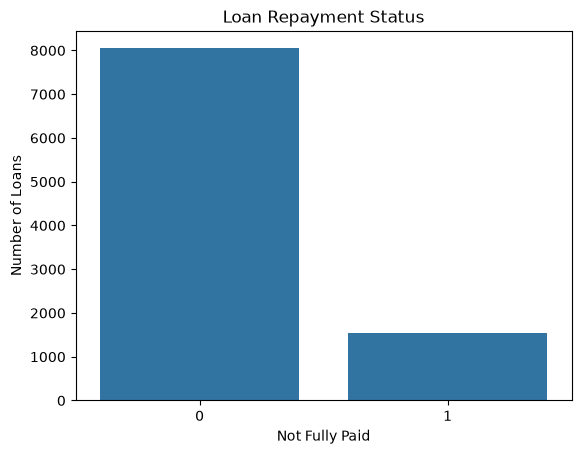

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="not.fully.paid", data=df)

plt.title("Loan Repayment Status")
plt.xlabel("Not Fully Paid")
plt.ylabel("Number of Loans")
plt.show()

In [20]:
df["purpose"].value_counts()

purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64

In [23]:
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [24]:
X = df.drop("not.fully.paid" , axis=1)
y = df["not.fully.paid"]

In [32]:
X.shape , y.shape

((9578, 13), (9578,))

In [33]:
X = pd.get_dummies(X, columns=["purpose"], drop_first=True)

In [36]:
X.shape

(9578, 18)

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [38]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((7662, 18), (1916, 18), (7662,), (1916,))

In [40]:
y_train.value_counts(normalize=True) * 100

not.fully.paid
0    83.998956
1    16.001044
Name: proportion, dtype: float64

In [41]:
y_test.value_counts(normalize=True) * 100

not.fully.paid
0    83.977035
1    16.022965
Name: proportion, dtype: float64

In [42]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train , y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

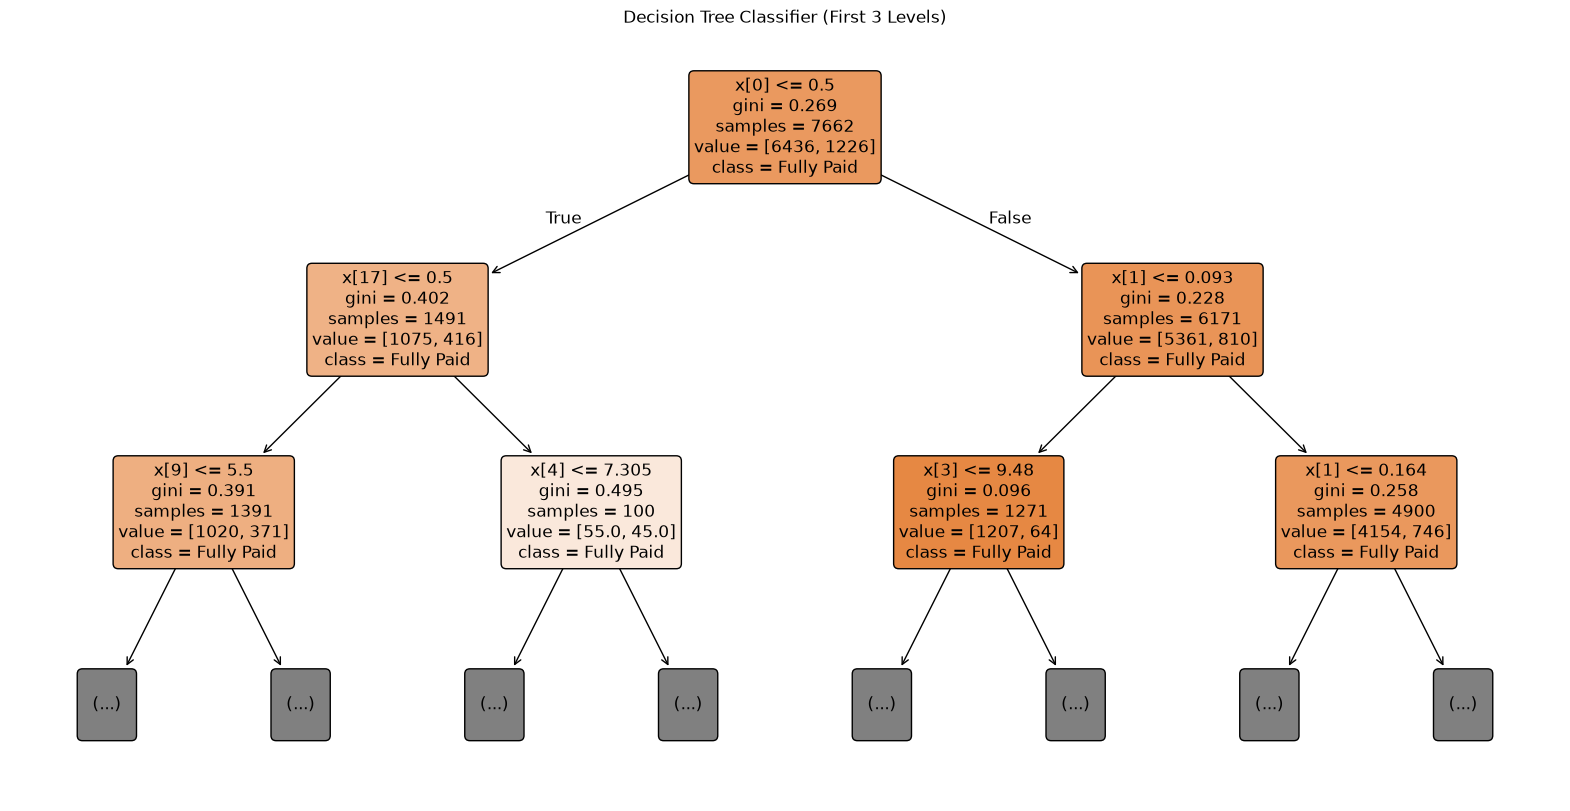

In [52]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    # feature_names=X.columns,
    class_names=["Fully Paid", "Not Fully Paid"],
    filled=True,
    rounded=True,
    max_depth=2
)

plt.title("Decision Tree Classifier (First 3 Levels)")
plt.show()

In [43]:
y_pred = dt.predict(X_test)

In [44]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test , y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.738517745302714


In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1341  268]
 [ 233   74]]


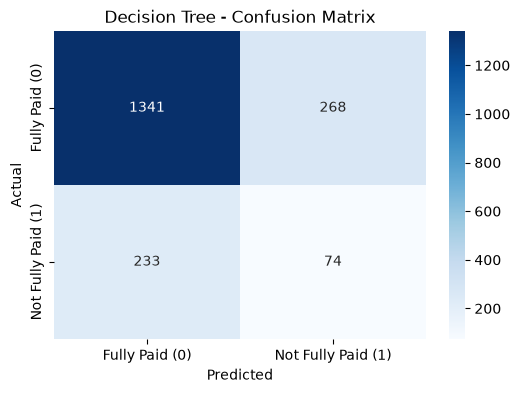

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fully Paid (0)", "Not Fully Paid (1)"],
    yticklabels=["Fully Paid (0)", "Not Fully Paid (1)"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

In [48]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.83      0.84      1609
           1       0.22      0.24      0.23       307

    accuracy                           0.74      1916
   macro avg       0.53      0.54      0.54      1916
weighted avg       0.75      0.74      0.74      1916



In [49]:
print("Training Accuracy:", dt.score(X_train, y_train))
print("Testing Accuracy:", dt.score(X_test, y_test))

Training Accuracy: 1.0
Testing Accuracy: 0.738517745302714


In [53]:
dt_pruned = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_pruned.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [54]:
y_pred_pruned = dt_pruned.predict(X_test)

In [55]:
print("Training Accuracy:", dt_pruned.score(X_train, y_train))
print("Testing Accuracy:", dt_pruned.score(X_test, y_test))

Training Accuracy: 0.8466457843904985
Testing Accuracy: 0.837160751565762


In [56]:
print(classification_report(y_test, y_pred_pruned))

              precision    recall  f1-score   support

           0       0.84      0.99      0.91      1609
           1       0.40      0.03      0.06       307

    accuracy                           0.84      1916
   macro avg       0.62      0.51      0.49      1916
weighted avg       0.77      0.84      0.77      1916



In [57]:
dt_balanced = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

dt_balanced.fit(X_train, y_train)

y_pred_balanced = dt_balanced.predict(X_test)

In [58]:
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.89      0.62      0.73      1609
           1       0.23      0.58      0.32       307

    accuracy                           0.62      1916
   macro avg       0.56      0.60      0.53      1916
weighted avg       0.78      0.62      0.67      1916



In [59]:
from sklearn.model_selection import GridSearchCV

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)


In [60]:
param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

In [61]:
grid_search = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Contr

In [62]:
print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best F1 Score: 0.33191152603399504


In [63]:
best_dt = grid_search.best_estimator_

y_pred_best = best_dt.predict(X_test)

In [64]:
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           0       0.88      0.62      0.73      1609
           1       0.23      0.58      0.32       307

    accuracy                           0.61      1916
   macro avg       0.56      0.60      0.53      1916
weighted avg       0.78      0.61      0.67      1916



In [65]:
dt_entropy = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    class_weight="balanced",
    criterion="entropy",
    random_state=42
)

dt_entropy.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_

In [66]:
y_pred_entropy = dt_entropy.predict(X_test)

In [67]:
print(classification_report(y_test, y_pred_entropy))

              precision    recall  f1-score   support

           0       0.88      0.64      0.74      1609
           1       0.23      0.57      0.33       307

    accuracy                           0.62      1916
   macro avg       0.56      0.60      0.53      1916
weighted avg       0.78      0.62      0.67      1916



In [68]:
path = best_dt.cost_complexity_pruning_path(X_train , y_train)

ccp_alphas = path.ccp_alphas

print(ccp_alphas)

[0.         0.00023963 0.00035575 0.00050578 0.00057793 0.00059322
 0.00059623 0.0006035  0.00073341 0.00073837 0.00086149 0.00096066
 0.00098671 0.00101075 0.0011623  0.00146126 0.00152812 0.00241544
 0.00298885 0.00352305 0.01328619 0.02195194]


In [69]:
from sklearn.metrics import f1_score

train_scores = []
test_scores = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        class_weight="balanced",
        criterion="entropy",
        ccp_alpha=alpha,
        random_state=42
    )

    model.fit(X_train, y_train)

In [70]:
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)
train_scores.append(f1_score(y_train, train_pred))
test_scores.append(f1_score(y_test, test_pred))

In [71]:
print("Test F1 Scores:")
for alpha, score in zip(ccp_alphas, test_scores):
    print(alpha, "->", score)

Test F1 Scores:
0.0 -> 0.3007438894792774


In [72]:
best_index = test_scores.index(max(test_scores))

print("Best ccp_alpha:", ccp_alphas[best_index])
print("Best Test F1:", test_scores[best_index])

Best ccp_alpha: 0.0
Best Test F1: 0.3007438894792774


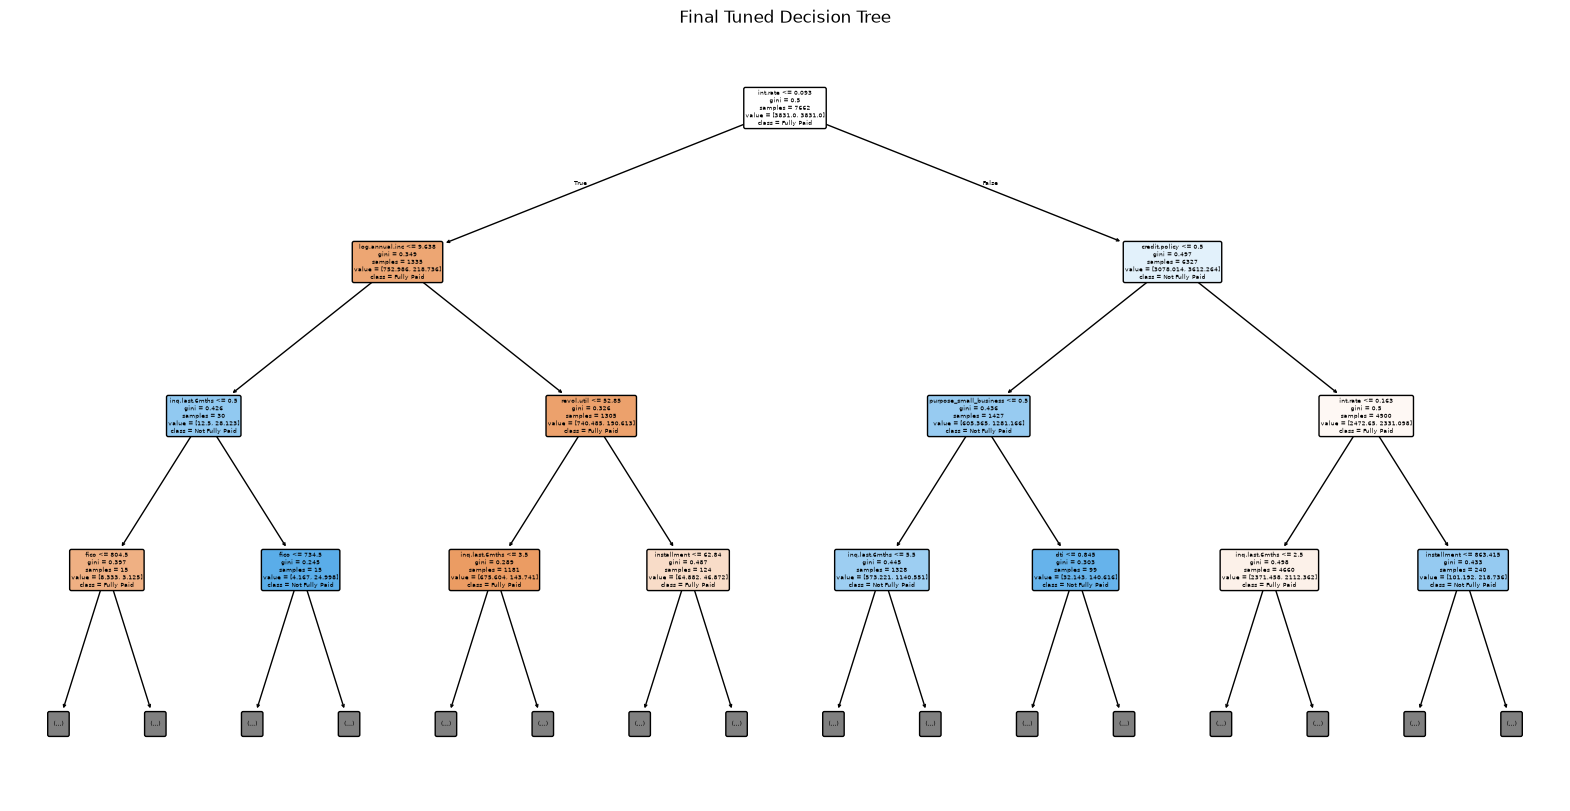

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    best_dt,
    feature_names=X.columns, # type: ignore
    class_names=["Fully Paid", "Not Fully Paid"],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Final Tuned Decision Tree")
plt.show()

In [74]:
feature_importance = best_dt.feature_importances_

for feature, importance in zip(X.columns, feature_importance):
    print(feature, ":", importance)

credit.policy : 0.21918570698685624
int.rate : 0.4377432697267708
installment : 0.05734838151293092
log.annual.inc : 0.06395486383738119
dti : 0.012181014519765079
fico : 0.02795199112220426
days.with.cr.line : 0.009836111459794909
revol.bal : 0.010125801848396019
revol.util : 0.03474416653123368
inq.last.6mths : 0.09576327544155909
delinq.2yrs : 0.0
pub.rec : 0.0
purpose_credit_card : 0.0
purpose_debt_consolidation : 0.01627794216244025
purpose_educational : 0.0
purpose_home_improvement : 0.0
purpose_major_purchase : 0.0
purpose_small_business : 0.014887474850667465


In [75]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_dt.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=True
)

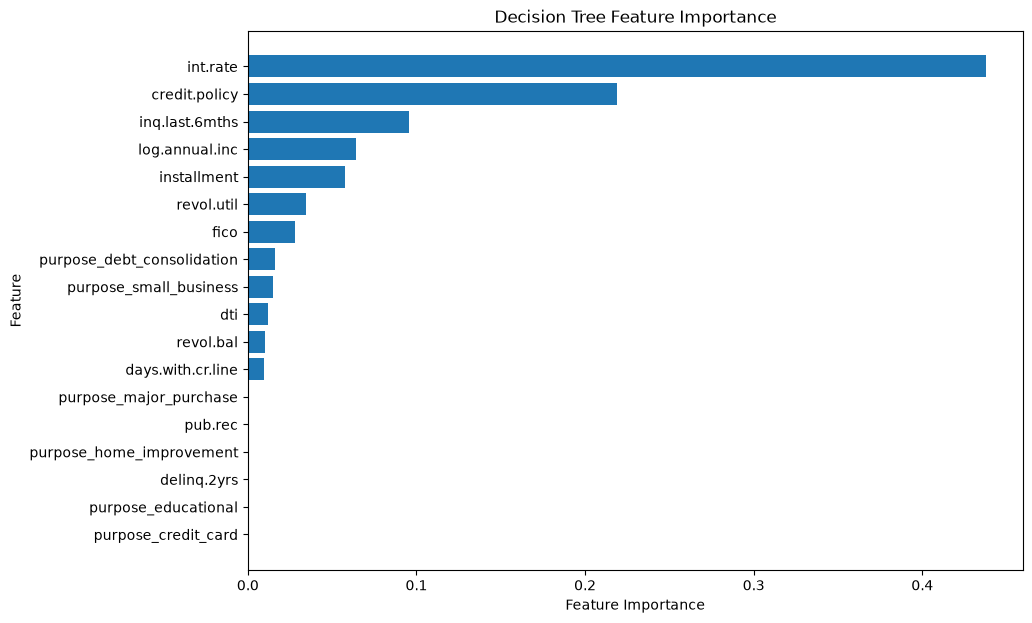

In [76]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")

plt.show()

In [78]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_final = best_dt.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall   :", recall_score(y_test, y_pred_final))
print("F1 Score :", f1_score(y_test, y_pred_final))

Accuracy : 0.6143006263048016
Precision: 0.22519083969465647
Recall   : 0.5765472312703583
F1 Score : 0.32387923147301007


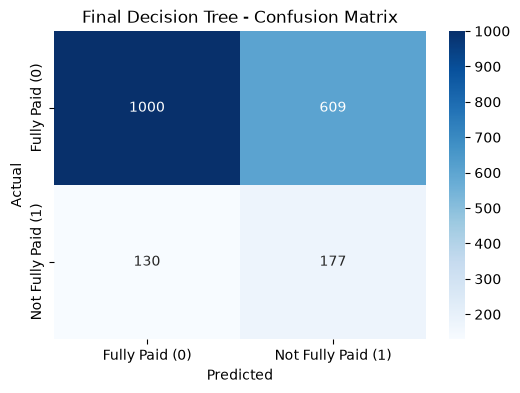

In [79]:
cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fully Paid (0)", "Not Fully Paid (1)"],
    yticklabels=["Fully Paid (0)", "Not Fully Paid (1)"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Decision Tree - Confusion Matrix")

plt.show()

Decision Tree Regression

In [80]:
X_reg = df.drop("int.rate", axis=1)
y_reg = df["int.rate"]

print("X shape:", X_reg.shape)
print("y shape:", y_reg.shape)

X shape: (9578, 13)
y shape: (9578,)


In [81]:
X_reg = pd.get_dummies(
    X_reg,
    columns=["purpose"],
    drop_first=True
)

print("X shape:", X_reg.shape)

X shape: (9578, 18)


In [82]:
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

In [83]:
print("X_reg_train:", X_reg_train.shape)
print("X_reg_test:", X_reg_test.shape)
print("y_reg_train:", y_reg_train.shape)
print("y_reg_test:", y_reg_test.shape)

X_reg_train: (7662, 18)
X_reg_test: (1916, 18)
y_reg_train: (7662,)
y_reg_test: (1916,)


In [84]:
from sklearn.tree import DecisionTreeRegressor

dt_reg = DecisionTreeRegressor(
    random_state=42
)

dt_reg.fit(X_reg_train, y_reg_train)

y_reg_pred = dt_reg.predict(X_reg_test)

In [85]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred))
r2 = r2_score(y_reg_test, y_reg_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 0.0121241127348643
RMSE: 0.018104482483974133
R²  : 0.5238815866182618


In [86]:
print("Training R²:", dt_reg.score(X_reg_train, y_reg_train))
print("Testing R² :", dt_reg.score(X_reg_test, y_reg_test))

Training R²: 1.0
Testing R² : 0.5238815866182618


In [87]:
dt_reg_pruned = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

dt_reg_pruned.fit(X_reg_train, y_reg_train)

y_reg_pred_pruned = dt_reg_pruned.predict(X_reg_test)

In [88]:
print("Training R²:", dt_reg_pruned.score(X_reg_train, y_reg_train))
print("Testing R² :", dt_reg_pruned.score(X_reg_test, y_reg_test))

Training R²: 0.6856529627910651
Testing R² : 0.6522745337457068


In [89]:
mae_pruned = mean_absolute_error(y_reg_test, y_reg_pred_pruned)
rmse_pruned = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_pruned))
r2_pruned = r2_score(y_reg_test, y_reg_pred_pruned)

In [90]:
print("MAE :", mae_pruned)
print("RMSE:", rmse_pruned)
print("R²  :", r2_pruned)

MAE : 0.011346078609937114
RMSE: 0.01547201491004751
R²  : 0.6522745337457068


In [91]:
dt_reg_base = DecisionTreeRegressor(
    random_state=42
)

param_grid_reg = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

In [92]:
grid_reg = GridSearchCV(
    estimator=dt_reg_base,
    param_grid=param_grid_reg,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_reg.fit(X_reg_train, y_reg_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Contr

In [93]:
print("Best Parameters:", grid_reg.best_params_)
print("Best CV R²:", grid_reg.best_score_)

Best Parameters: {'max_depth': 7, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV R²: 0.6755888357012712


In [94]:
best_dt_reg = grid_reg.best_estimator_

y_reg_pred_best = best_dt_reg.predict(X_reg_test)

In [95]:
print("Test R²:", r2_score(y_reg_test, y_reg_pred_best))
print("MAE:", mean_absolute_error(y_reg_test, y_reg_pred_best))
print("RMSE:", np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_best)))

Test R²: 0.6662216582903329
MAE: 0.010860828330911785
RMSE: 0.015158551463575764


In [96]:
path_reg = best_dt_reg.cost_complexity_pruning_path(
    X_reg_train,
    y_reg_train
)

ccp_alphas_reg = path_reg.ccp_alphas

print(ccp_alphas_reg)

[0.00000000e+00 1.32911959e-08 2.19222653e-08 2.79413055e-08
 3.61553026e-08 4.10282864e-08 5.24723590e-08 6.00093974e-08
 8.45764813e-08 8.95608711e-08 9.06297470e-08 9.22145313e-08
 9.61892314e-08 1.02344286e-07 1.09879328e-07 1.16225849e-07
 1.16440268e-07 1.20150211e-07 1.36694435e-07 1.43516957e-07
 2.02207654e-07 2.22413841e-07 2.32323141e-07 2.51306634e-07
 2.71328099e-07 3.04533194e-07 3.06253690e-07 3.32517990e-07
 3.42754523e-07 3.57183634e-07 3.65472433e-07 3.67374079e-07
 3.86112683e-07 3.90518474e-07 4.16007427e-07 4.42187842e-07
 4.52430310e-07 4.55883237e-07 4.66884134e-07 4.70743351e-07
 4.73125047e-07 4.74741273e-07 4.80683438e-07 4.88015762e-07
 5.12614681e-07 5.21470125e-07 5.56325282e-07 5.58035674e-07
 5.76425505e-07 5.87258736e-07 5.90759594e-07 6.05251059e-07
 6.34744292e-07 6.40959122e-07 6.44221059e-07 7.18764843e-07
 7.26789411e-07 7.26882008e-07 7.31627925e-07 7.43932738e-07
 7.59933138e-07 7.69231572e-07 8.39853917e-07 8.40341507e-07
 9.26657376e-07 1.002429

In [98]:
train_scores_reg = []
test_scores_reg = []

for alpha in ccp_alphas_reg:

    model = DecisionTreeRegressor(
        max_depth=7,
        min_samples_leaf=5,
        min_samples_split=2,
        ccp_alpha=alpha,
        random_state=42
    )

    model.fit(X_reg_train, y_reg_train)

    train_pred = model.predict(X_reg_train)
    test_pred = model.predict(X_reg_test)

    train_scores_reg.append(
        r2_score(y_reg_train, train_pred)
    )

    test_scores_reg.append(
        r2_score(y_reg_test, test_pred)
    )

In [99]:
best_alpha_index = test_scores_reg.index(
    max(test_scores_reg)
)

best_alpha_reg = ccp_alphas_reg[best_alpha_index]

In [100]:
print("Best ccp_alpha:", best_alpha_reg)
print("Best Test R²:", test_scores_reg[best_alpha_index])

Best ccp_alpha: 4.731250468775111e-07
Best Test R²: 0.6741542710925796


In [101]:
best_dt_reg_pruned = DecisionTreeRegressor(
    max_depth=7,
    min_samples_leaf=5,
    min_samples_split=2,
    ccp_alpha=4.731250468775111e-07,
    random_state=42
)

best_dt_reg_pruned.fit(X_reg_train, y_reg_train)

y_reg_pred_pruned_final = best_dt_reg_pruned.predict(X_reg_test)

In [102]:
mae_final = mean_absolute_error(
    y_reg_test,
    y_reg_pred_pruned_final
)

rmse_final = np.sqrt(
    mean_squared_error(
        y_reg_test,
        y_reg_pred_pruned_final
    )
)

r2_final = r2_score(
    y_reg_test,
    y_reg_pred_pruned_final
)

In [103]:
print("Final MAE :", mae_final)
print("Final RMSE:", rmse_final)
print("Final R²  :", r2_final)

Final MAE : 0.010777069915558608
Final RMSE: 0.014977338405742485
Final R²  : 0.6741542710925796


In [104]:
DecisionTreeRegressor(
    max_depth=7,
    min_samples_leaf=5,
    min_samples_split=2,
    ccp_alpha=4.731250468775111e-07,
    random_state=42
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",7
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",4.731250468775111e-07
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.-

In [105]:
feature_importance_reg = best_dt_reg_pruned.feature_importances_

for feature, importance in zip(
    X_reg.columns,
    feature_importance_reg
):
    print(feature, ":", importance)

credit.policy : 0.0
installment : 0.20335519682624523
log.annual.inc : 0.0039647466543263525
dti : 0.015649472019642664
fico : 0.7237679497861762
days.with.cr.line : 0.0025122294317147897
revol.bal : 0.0009865822050959788
revol.util : 0.013906456805351262
inq.last.6mths : 0.013199472224189355
delinq.2yrs : 0.0
pub.rec : 0.0
not.fully.paid : 0.001080657224886046
purpose_credit_card : 0.0
purpose_debt_consolidation : 0.0
purpose_educational : 0.0
purpose_home_improvement : 0.0
purpose_major_purchase : 0.0
purpose_small_business : 0.021577236822372125


In [106]:
X_reg = df.drop(
    ["int.rate", "not.fully.paid"],
    axis=1
)

In [107]:
X_reg = pd.get_dummies(
    X_reg,
    columns=["purpose"],
    drop_first=True
)

print("X shape:", X_reg.shape)

X shape: (9578, 17)


In [108]:
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

In [109]:
print("X_reg_train:", X_reg_train.shape)
print("X_reg_test :", X_reg_test.shape)
print("y_reg_train:", y_reg_train.shape)
print("y_reg_test :", y_reg_test.shape)

X_reg_train: (7662, 17)
X_reg_test : (1916, 17)
y_reg_train: (7662,)
y_reg_test : (1916,)


In [110]:
clean_dt_reg = DecisionTreeRegressor(
    max_depth=7,
    min_samples_leaf=5,
    min_samples_split=2,
    ccp_alpha=4.731250468775111e-07,
    random_state=42
)

clean_dt_reg.fit(X_reg_train, y_reg_train)

y_clean_pred = clean_dt_reg.predict(X_reg_test)

print("Model trained successfully.")

Model trained successfully.


In [111]:
clean_mae = mean_absolute_error(
    y_reg_test,
    y_clean_pred
)

clean_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        y_clean_pred
    )
)

clean_r2 = r2_score(
    y_reg_test,
    y_clean_pred
)

In [112]:
print("Clean Model MAE :", clean_mae)
print("Clean Model RMSE:", clean_rmse)
print("Clean Model R²  :", clean_r2)

Clean Model MAE : 0.01086564807109828
Clean Model RMSE: 0.015113823828039465
Clean Model R²  : 0.6681884808760161


In [113]:
feature_importance_clean = clean_dt_reg.feature_importances_

for feature, importance in zip(
    X_reg.columns,
    feature_importance_clean
):
    print(feature, ":", importance)

credit.policy : 0.0
installment : 0.20433211741765153
log.annual.inc : 0.0014071057929747942
dti : 0.01564548120680496
fico : 0.7246485024226034
days.with.cr.line : 0.0034064774729933196
revol.bal : 0.0009863306141790513
revol.util : 0.014806144525900103
inq.last.6mths : 0.013196106192185125
delinq.2yrs : 0.0
pub.rec : 0.0
purpose_credit_card : 0.0
purpose_debt_consolidation : 0.0
purpose_educational : 0.0
purpose_home_improvement : 0.0
purpose_major_purchase : 0.0
purpose_small_business : 0.021571734354707724


In [114]:
feature_importance_clean = clean_dt_reg.feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": X_reg.columns,
    "Importance": feature_importance_clean
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

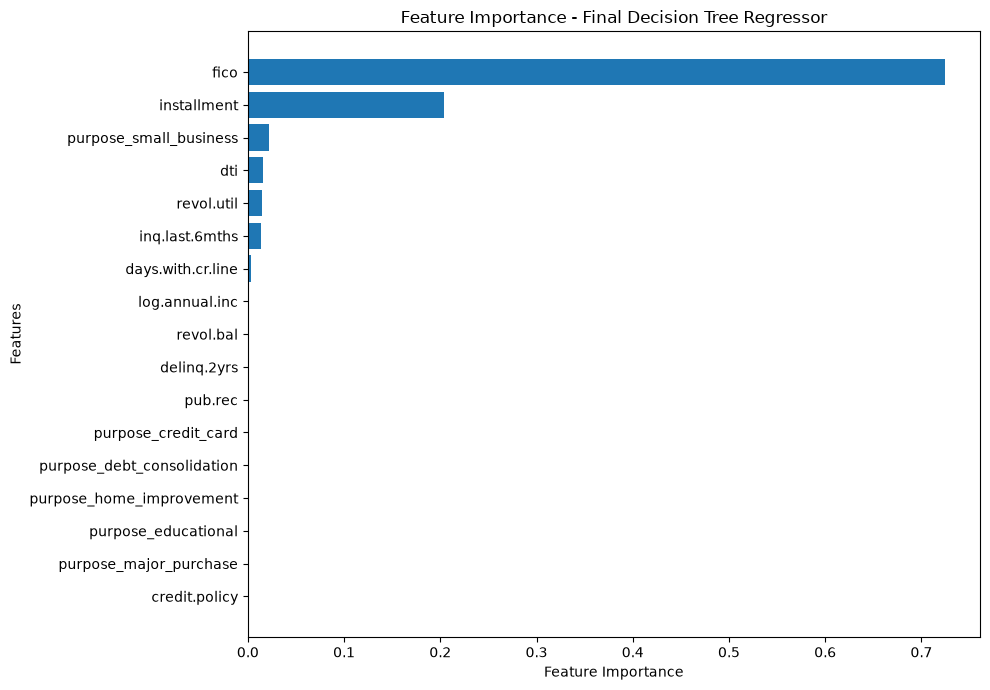

In [115]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance - Final Decision Tree Regressor")

plt.tight_layout()
plt.show()

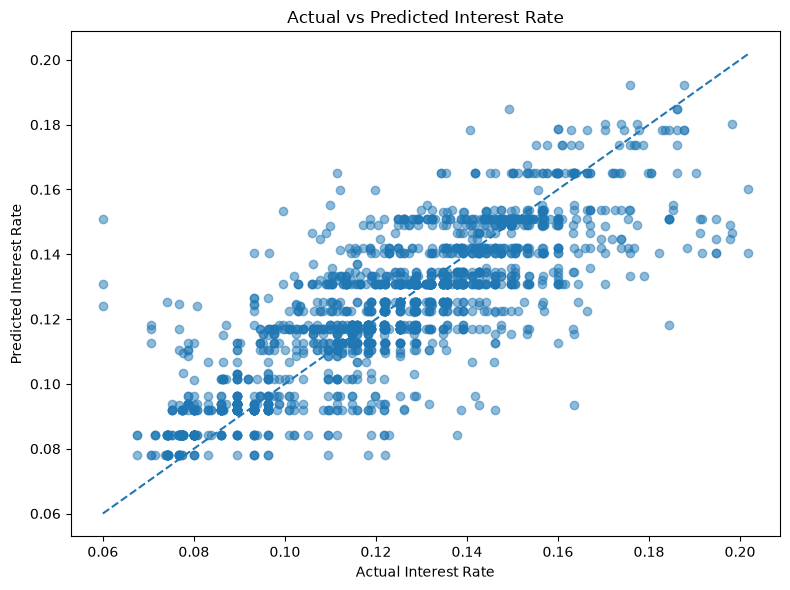

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test,
    y_clean_pred,
    alpha=0.5
)

plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Interest Rate")
plt.ylabel("Predicted Interest Rate")
plt.title("Actual vs Predicted Interest Rate")

plt.tight_layout()
plt.show()

In [120]:
new_loan = pd.DataFrame({
    "credit.policy": [1],
    "purpose": ["debt_consolidation"],
    "installment": [300],
    "log.annual.inc": [10.5],
    "dti": [15.0],
    "fico": [720],
    "days.with.cr.line": [5000],
    "revol.bal": [15000],
    "revol.util": [40.0],
    "inq.last.6mths": [1],
    "delinq.2yrs": [0],
    "pub.rec": [0]
})

new_loan = pd.get_dummies(
    new_loan,
    columns=["purpose"],
    drop_first=True
)

new_loan = new_loan.reindex(
    columns=X_reg.columns,
    fill_value=0
)

predicted_rate = clean_dt_reg.predict(new_loan)

In [121]:
print("Predicted Interest Rate:", predicted_rate[0])
print("Predicted Interest Rate (%):", predicted_rate[0] * 100)

Predicted Interest Rate: 0.110403144654088
Predicted Interest Rate (%): 11.0403144654088
